# X-MAD: A Public Multi-Anatomy X-ray Dataset for Self-Supervised Learning in Low-Resource Radiographic Imaging
### Complete Pipeline: Training + All Paper Figures

## Step 1: Install & Import Libraries

In [ ]:
!pip install timm umap-learn -q

import os, random, zipfile
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.patches import FancyArrowPatch
import seaborn as sns
from PIL import Image
from tqdm import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, random_split
import torchvision.transforms as transforms
import torchvision.models as models
from torchvision.utils import make_grid

from sklearn.manifold import TSNE
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, silhouette_samples
from sklearn.decomposition import PCA
import umap

from google.colab import drive

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {device}')

# Reproducibility
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)
random.seed(SEED)

Using device: cuda


## Step 2: Mount Google Drive & Load Dataset

In [ ]:
drive.mount('/content/drive')

# ======================================================
# CHANGE THIS PATH to your dataset folder in Google Drive
DATASET_PATH = '/content/drive/MyDrive/xray_img/Xray_img'
# ======================================================

# Count images
image_extensions = ('.jpg', '.jpeg', '.png', '.bmp', '.tiff')
all_images = []
for root, dirs, files in os.walk(DATASET_PATH):
    for f in files:
        if f.lower().endswith(image_extensions):
            all_images.append(os.path.join(root, f))

print(f'Total X-ray images found: {len(all_images)}')

Mounted at /content/drive
Total X-ray images found: 5608


## Step 3: Dataset Class & Transforms

In [ ]:
IMG_SIZE = 224
BATCH_SIZE = 32
MASK_RATIO = 0.75  # 75% of patches are masked
PATCH_SIZE = 16
NUM_PATCHES = (IMG_SIZE // PATCH_SIZE) ** 2  # 196 patches

transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.Grayscale(num_output_channels=3),  # X-rays are grayscale
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

class XRayDataset(Dataset):
    def __init__(self, image_paths, transform=None):
        self.image_paths = image_paths
        self.transform = transform

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        img = Image.open(self.image_paths[idx]).convert('RGB')
        if self.transform:
            img = self.transform(img)
        return img, self.image_paths[idx]

dataset = XRayDataset(all_images, transform=transform)
train_size = int(0.8 * len(dataset))
val_size = len(dataset) - train_size
train_dataset, val_dataset = random_split(dataset, [train_size, val_size])

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)

print(f'Train: {train_size} | Val: {val_size}')

Train: 4486 | Val: 1122


## Step 4: Masked Autoencoder (MAE) Model

In [ ]:
class MaskedAutoencoder(nn.Module):
    def __init__(self, img_size=224, patch_size=16, in_chans=3,
                 embed_dim=768, encoder_depth=6, encoder_heads=8,
                 decoder_dim=256, decoder_depth=4, decoder_heads=8,
                 mask_ratio=0.75):
        super().__init__()
        self.patch_size = patch_size
        self.mask_ratio = mask_ratio
        num_patches = (img_size // patch_size) ** 2
        patch_dim = in_chans * patch_size * patch_size

        # Patch embedding
        self.patch_embed = nn.Linear(patch_dim, embed_dim)
        self.pos_embed = nn.Parameter(torch.zeros(1, num_patches, embed_dim))
        nn.init.trunc_normal_(self.pos_embed, std=0.02)

        # Encoder (Transformer)
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=embed_dim, nhead=encoder_heads,
            dim_feedforward=embed_dim*4, dropout=0.1,
            batch_first=True, norm_first=True
        )
        self.encoder = nn.TransformerEncoder(encoder_layer, num_layers=encoder_depth)
        self.encoder_norm = nn.LayerNorm(embed_dim)

        # Decoder
        self.decoder_embed = nn.Linear(embed_dim, decoder_dim)
        self.mask_token = nn.Parameter(torch.zeros(1, 1, decoder_dim))
        self.decoder_pos_embed = nn.Parameter(torch.zeros(1, num_patches, decoder_dim))
        nn.init.trunc_normal_(self.decoder_pos_embed, std=0.02)
        nn.init.trunc_normal_(self.mask_token, std=0.02)

        decoder_layer = nn.TransformerEncoderLayer(
            d_model=decoder_dim, nhead=decoder_heads,
            dim_feedforward=decoder_dim*4, dropout=0.1,
            batch_first=True, norm_first=True
        )
        self.decoder = nn.TransformerEncoder(decoder_layer, num_layers=decoder_depth)
        self.decoder_norm = nn.LayerNorm(decoder_dim)
        self.decoder_pred = nn.Linear(decoder_dim, patch_dim)

    def patchify(self, imgs):
        p = self.patch_size
        B, C, H, W = imgs.shape
        h = w = H // p
        x = imgs.reshape(B, C, h, p, w, p)
        x = x.permute(0, 2, 4, 1, 3, 5).reshape(B, h*w, C*p*p)
        return x

    def unpatchify(self, x, C=3):
        p = self.patch_size
        B, N, _ = x.shape
        h = w = int(N ** 0.5)
        x = x.reshape(B, h, w, C, p, p)
        x = x.permute(0, 3, 1, 4, 2, 5).reshape(B, C, h*p, w*p)
        return x

    def random_masking(self, x):
        B, N, D = x.shape
        len_keep = int(N * (1 - self.mask_ratio))
        noise = torch.rand(B, N, device=x.device)
        ids_shuffle = torch.argsort(noise, dim=1)
        ids_restore = torch.argsort(ids_shuffle, dim=1)
        ids_keep = ids_shuffle[:, :len_keep]
        x_masked = torch.gather(x, 1, ids_keep.unsqueeze(-1).expand(-1, -1, D))
        mask = torch.ones(B, N, device=x.device)
        mask[:, :len_keep] = 0
        mask = torch.gather(mask, 1, ids_restore)
        return x_masked, mask, ids_restore

    def forward_encoder(self, x):
        patches = self.patchify(x)
        tokens = self.patch_embed(patches) + self.pos_embed
        tokens_masked, mask, ids_restore = self.random_masking(tokens)
        encoded = self.encoder_norm(self.encoder(tokens_masked))
        return encoded, mask, ids_restore

    def forward_decoder(self, encoded, ids_restore):
        B, L, _ = encoded.shape
        N = ids_restore.shape[1]
        x = self.decoder_embed(encoded)
        mask_tokens = self.mask_token.expand(B, N - L, -1)
        x_full = torch.cat([x, mask_tokens], dim=1)
        x_full = torch.gather(x_full, 1, ids_restore.unsqueeze(-1).expand(-1, -1, x_full.shape[2]))
        x_full = x_full + self.decoder_pos_embed
        decoded = self.decoder_norm(self.decoder(x_full))
        pred = self.decoder_pred(decoded)
        return pred

    def forward(self, imgs):
        encoded, mask, ids_restore = self.forward_encoder(imgs)
        pred = self.forward_decoder(encoded, ids_restore)
        target = self.patchify(imgs)
        loss = ((pred - target) ** 2)
        loss = (loss * mask.unsqueeze(-1)).sum() / mask.sum()
        return loss, pred, mask

    def get_features(self, imgs):
        """Extract encoder features (no masking) for downstream analysis."""
        self.eval()
        with torch.no_grad():
            patches = self.patchify(imgs)
            tokens = self.patch_embed(patches) + self.pos_embed
            encoded = self.encoder_norm(self.encoder(tokens))
            features = encoded.mean(dim=1)  # global average pooling
        return features

model = MaskedAutoencoder().to(device)
total_params = sum(p.numel() for p in model.parameters()) / 1e6
print(f'Model Parameters: {total_params:.1f}M')

/tmp/ipykernel_1062/1563756672.py:23: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.encoder = nn.TransformerEncoder(encoder_layer, num_layers=encoder_depth)
/tmp/ipykernel_1062/1563756672.py:38: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.decoder = nn.TransformerEncoder(decoder_layer, num_layers=decoder_depth)


Model Parameters: 46.9M


## Step 5: Training

In [ ]:
import os

EPOCHS = 30
LR = 1e-4
CHECKPOINT_DIR = '/content/drive/MyDrive/xray_checkpoints'
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

def save_checkpoint(epoch, model, optimizer, scheduler, train_losses, val_losses, lr_history):
    checkpoint = {
        'epoch': epoch,
        'model_state_dict': model.state_dict(),
        'optimizer_state_dict': optimizer.state_dict(),
        'scheduler_state_dict': scheduler.state_dict(),
        'train_losses': train_losses,
        'val_losses': val_losses,
        'lr_history': lr_history,
    }
    path = os.path.join(CHECKPOINT_DIR, f'checkpoint_epoch_{epoch}.pth')
    torch.save(checkpoint, path)
    print(f'✅ Checkpoint saved: checkpoint_epoch_{epoch}.pth')

optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=0.05)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)
train_losses, val_losses, lr_history = [], [], []

for epoch in range(EPOCHS):
    model.train()
    epoch_loss = 0
    for imgs, _ in tqdm(train_loader, desc=f'Epoch {epoch+1}/{EPOCHS}'):
        imgs = imgs.to(device)
        optimizer.zero_grad()
        loss, _, _ = model(imgs)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        epoch_loss += loss.item()

    avg_train = epoch_loss / len(train_loader)
    train_losses.append(avg_train)

    model.eval()
    val_loss = 0
    with torch.no_grad():
        for imgs, _ in val_loader:
            imgs = imgs.to(device)
            loss, _, _ = model(imgs)
            val_loss += loss.item()
    avg_val = val_loss / len(val_loader)
    val_losses.append(avg_val)
    lr_history.append(optimizer.param_groups[0]['lr'])
    scheduler.step()

    print(f'Epoch {epoch+1}: Train Loss={avg_train:.4f} | Val Loss={avg_val:.4f}')

    # Save checkpoint every 5 epochs
    if (epoch + 1) % 5 == 0:
        save_checkpoint(epoch+1, model, optimizer, scheduler,
                        train_losses, val_losses, lr_history)

# Save final model
save_checkpoint(epoch+1, model, optimizer, scheduler,
                train_losses, val_losses, lr_history)
torch.save(model.state_dict(), '/content/drive/MyDrive/mae_xray.pth')
print('Training complete!')

Epoch 1/30: 100%|██████████| 141/141 [11:56<00:00,  5.08s/it]


Epoch 1: Train Loss=814.8165 | Val Loss=619.2619


Epoch 2/30: 100%|██████████| 141/141 [06:38<00:00,  2.83s/it]


Epoch 2: Train Loss=597.8472 | Val Loss=592.6474


Epoch 3/30: 100%|██████████| 141/141 [06:29<00:00,  2.76s/it]


...

Epoch 28: Train Loss=392.5288 | Val Loss=403.4900


Epoch 29/30: 100%|██████████| 141/141 [06:36<00:00,  2.81s/it]


Epoch 29: Train Loss=389.4473 | Val Loss=405.4681


Epoch 30/30: 100%|██████████| 141/141 [06:24<00:00,  2.73s/it]


Epoch 30: Train Loss=391.4451 | Val Loss=404.9511
✅ Checkpoint saved: checkpoint_epoch_30.pth
✅ Checkpoint saved: checkpoint_epoch_30.pth
Training complete!


## Step 6: Extract Features for All Images

In [ ]:
all_features = []
all_paths = []

full_loader = DataLoader(dataset, batch_size=64, shuffle=False, num_workers=2)
model.eval()
with torch.no_grad():
    for imgs, paths in tqdm(full_loader, desc='Extracting features'):
        imgs = imgs.to(device)
        feats = model.get_features(imgs)
        all_features.append(feats.cpu().numpy())
        all_paths.extend(paths)

features = np.concatenate(all_features, axis=0)
print(f'Feature matrix: {features.shape}')

Extracting features: 100%|██████████| 88/88 [07:57<00:00,  5.42s/it]

Feature matrix: (5608, 768)


## Step 7: Clustering

In [ ]:
N_CLUSTERS = 5  # Adjust based on your domain knowledge

# Reduce dims first for clustering stability
pca_50 = PCA(n_components=50, random_state=SEED)
features_pca50 = pca_50.fit_transform(features)

kmeans = KMeans(n_clusters=N_CLUSTERS, random_state=SEED, n_init=10)
cluster_labels = kmeans.fit_predict(features_pca50)

sil_score = silhouette_score(features_pca50, cluster_labels)
print(f'Silhouette Score: {sil_score:.4f}')

Silhouette Score: 0.2350


---
# ALL FIGURES FOR PAPER
---

## FIGURE 1: Dataset Sample Grid

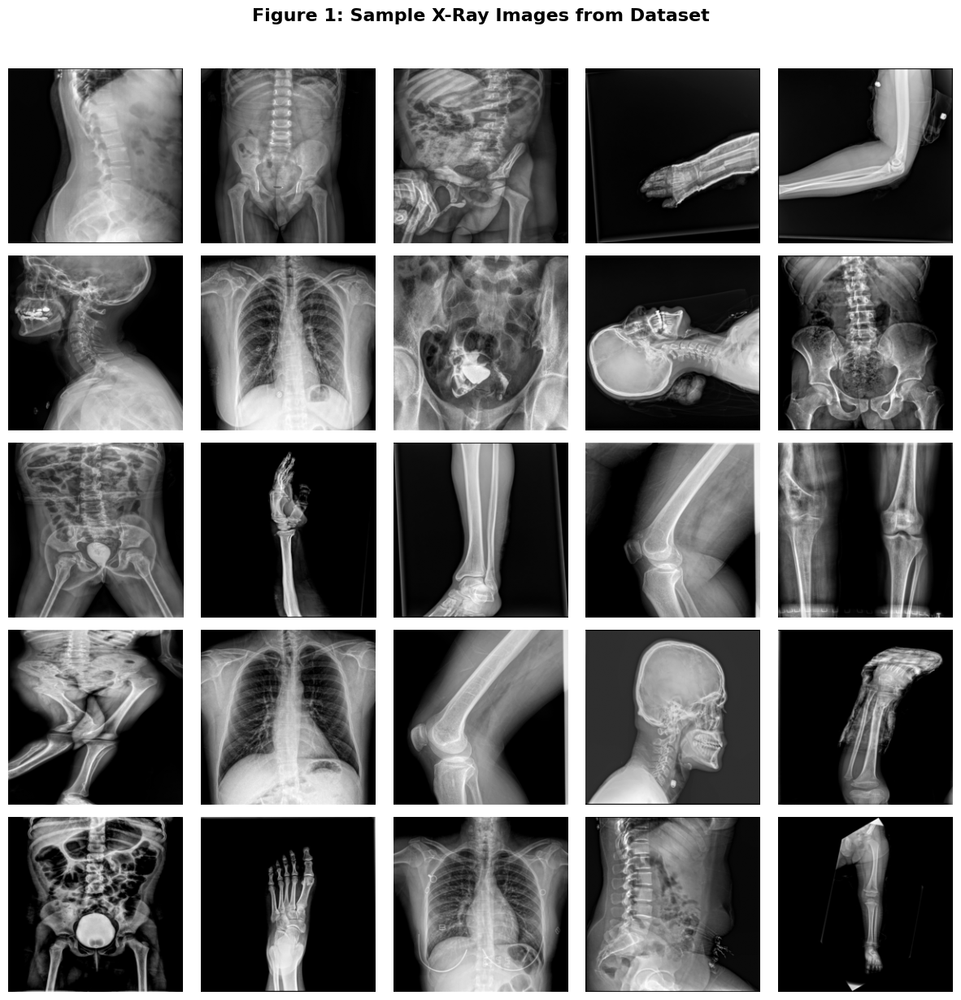

Figure 1 saved!


In [ ]:
def denormalize(tensor):
    mean = torch.tensor([0.485, 0.456, 0.406]).view(3,1,1)
    std  = torch.tensor([0.229, 0.224, 0.225]).view(3,1,1)
    return torch.clamp(tensor * std + mean, 0, 1)

sample_indices = random.sample(range(len(dataset)), 25)
sample_imgs = torch.stack([dataset[i][0] for i in sample_indices])
sample_imgs_dn = torch.stack([denormalize(img) for img in sample_imgs])

fig, axes = plt.subplots(5, 5, figsize=(12, 12))
fig.suptitle('Figure 1: Sample X-Ray Images from Dataset', fontsize=16, fontweight='bold', y=1.02)
for i, ax in enumerate(axes.flat):
    img = sample_imgs_dn[i].permute(1,2,0).numpy()
    img_gray = img.mean(axis=2)
    ax.imshow(img_gray, cmap='gray')
    ax.axis('off')
plt.tight_layout()
plt.savefig('figure1_dataset_samples.png', dpi=150, bbox_inches='tight')
plt.show()
print('Figure 1 saved!')

## FIGURE 2: Masking Visualization (Original → Masked → Reconstructed)

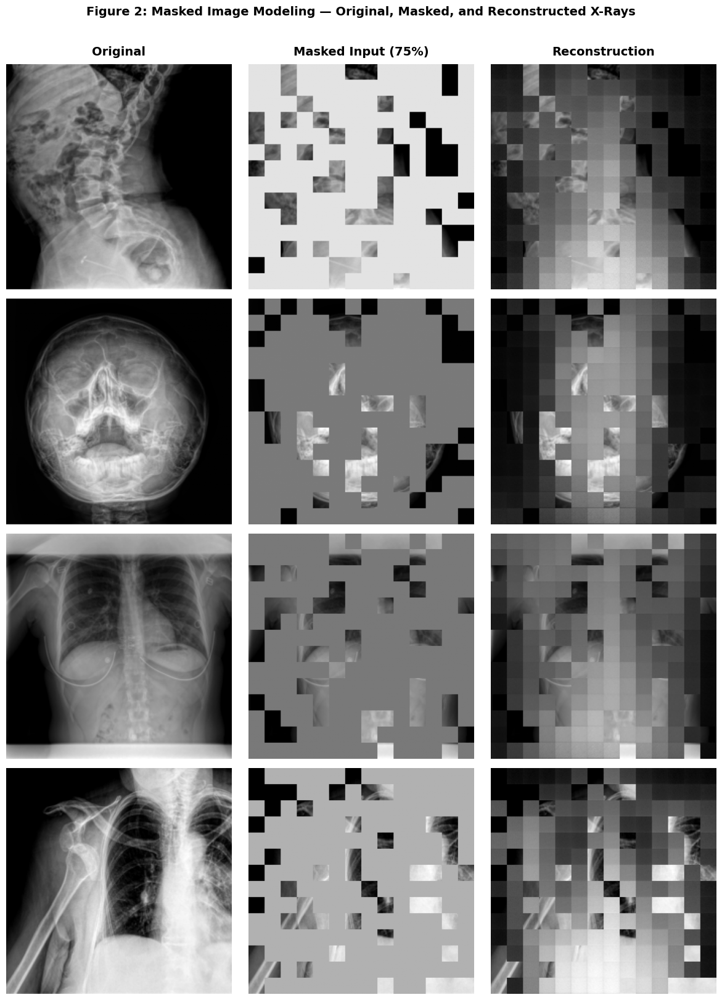

Figure 2 saved!


In [ ]:
model.eval()
sample_batch = torch.stack([dataset[i][0] for i in range(8)]).to(device)

with torch.no_grad():
    loss, pred, mask = model(sample_batch)

def reconstruct_image(model, img_tensor, mask_row, pred_row):
    """img_tensor: (1, C, H, W), mask_row: (1, N), pred_row: (1, N, patch_dim)"""
    with torch.no_grad():
        target = model.patchify(img_tensor)  # (1, N, patch_dim)

        # Masked image (zero out masked patches)
        masked_patches = target.clone()
        masked_patches[0][mask_row[0].bool()] = 0
        masked_img = model.unpatchify(masked_patches)[0]

        # Reconstructed image (fill masked patches with predictions)
        recon_patches = target.clone()
        recon_patches[0][mask_row[0].bool()] = pred_row[0][mask_row[0].bool()]
        recon_img = model.unpatchify(recon_patches)[0]

    return masked_img, recon_img

# Figure 2
model.eval()
sample_batch = torch.stack([dataset[i][0] for i in range(8)]).to(device)

with torch.no_grad():
    loss, pred, mask = model(sample_batch)

n_show = 4
fig, axes = plt.subplots(n_show, 3, figsize=(12, 4*n_show))
col_titles = ['Original', 'Masked Input (75%)', 'Reconstruction']
for j, title in enumerate(col_titles):
    axes[0, j].set_title(title, fontsize=14, fontweight='bold', pad=10)

for i in range(n_show):
    img_single = sample_batch[i].unsqueeze(0)   # (1, C, H, W)
    mask_single = mask[i].unsqueeze(0)           # (1, N)
    pred_single = pred[i].unsqueeze(0)           # (1, N, patch_dim)

    orig = denormalize(sample_batch[i].cpu())
    masked, recon = reconstruct_image(model, img_single, mask_single, pred_single)
    masked = denormalize(masked.cpu())
    recon  = denormalize(recon.cpu())

    for j, im in enumerate([orig, masked, recon]):
        img_np = im.permute(1, 2, 0).numpy().mean(axis=2)
        axes[i, j].imshow(img_np, cmap='gray')
        axes[i, j].axis('off')

fig.suptitle('Figure 2: Masked Image Modeling — Original, Masked, and Reconstructed X-Rays',
             fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('figure2_reconstruction.png', dpi=150, bbox_inches='tight')
plt.show()
print('Figure 2 saved!')

## FIGURE 3: Training & Validation Loss Curves

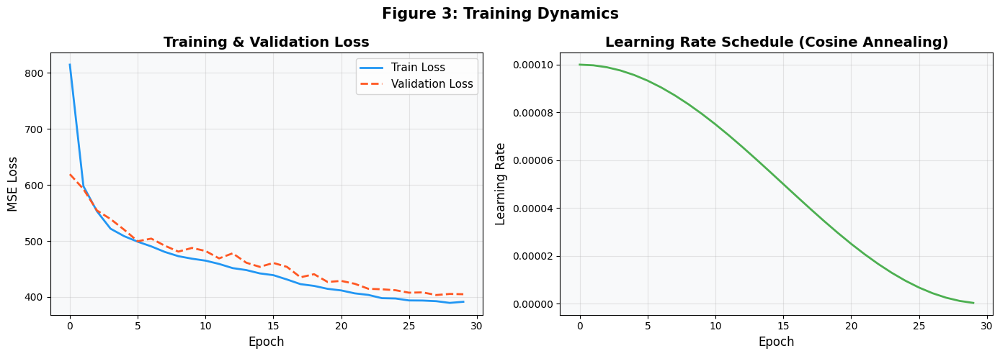

Figure 3 saved!


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Loss curves
ax = axes[0]
ax.plot(train_losses, label='Train Loss', color='#2196F3', linewidth=2)
ax.plot(val_losses, label='Validation Loss', color='#FF5722', linewidth=2, linestyle='--')
ax.set_xlabel('Epoch', fontsize=12)
ax.set_ylabel('MSE Loss', fontsize=12)
ax.set_title('Training & Validation Loss', fontsize=14, fontweight='bold')
ax.legend(fontsize=11)
ax.grid(True, alpha=0.3)
ax.set_facecolor('#f8f9fa')

# LR schedule
ax2 = axes[1]
ax2.plot(lr_history, color='#4CAF50', linewidth=2)
ax2.set_xlabel('Epoch', fontsize=12)
ax2.set_ylabel('Learning Rate', fontsize=12)
ax2.set_title('Learning Rate Schedule (Cosine Annealing)', fontsize=14, fontweight='bold')
ax2.grid(True, alpha=0.3)
ax2.set_facecolor('#f8f9fa')

fig.suptitle('Figure 3: Training Dynamics', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.savefig('figure3_training_curves.png', dpi=150, bbox_inches='tight')
plt.show()
print('Figure 3 saved!')

## FIGURE 4: t-SNE Feature Visualization

Running t-SNE...


/usr/local/lib/python3.12/dist-packages/sklearn/manifold/_t_sne.py:1164: FutureWarning: 'n_iter' was renamed to 'max_iter' in version 1.5 and will be removed in 1.7.
  warnings.warn(


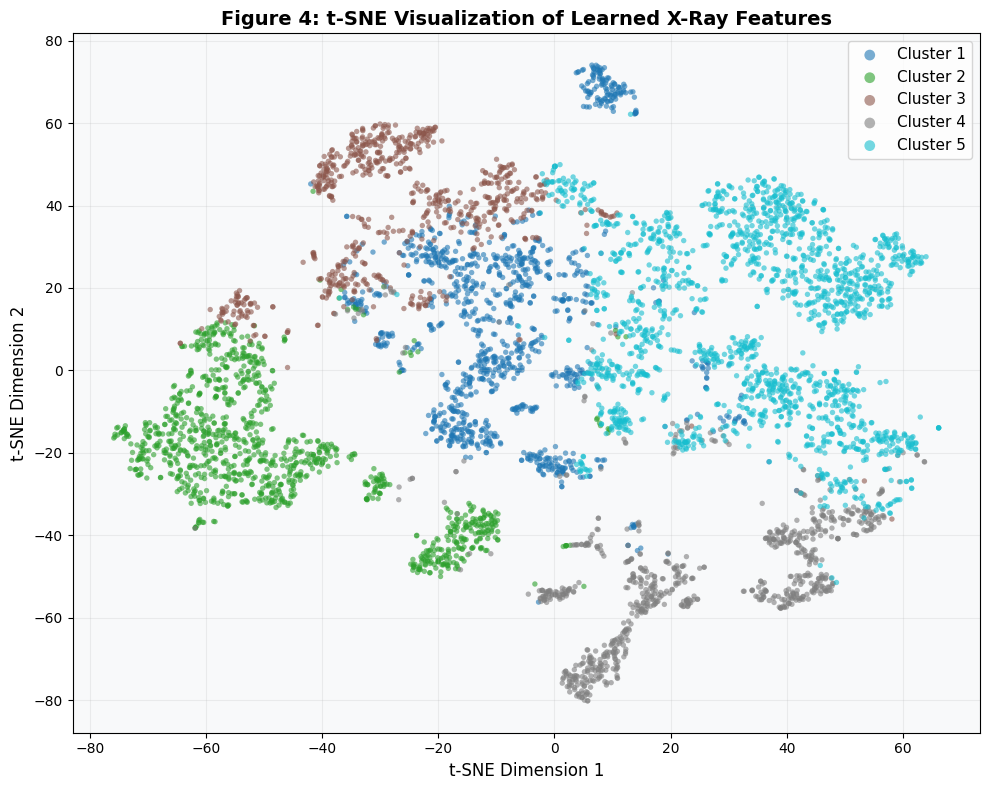

Figure 4 saved!


In [ ]:
print('Running t-SNE...')
tsne = TSNE(n_components=2, perplexity=30, random_state=SEED, n_iter=1000)
features_2d = tsne.fit_transform(features_pca50)

colors = plt.cm.tab10(np.linspace(0, 1, N_CLUSTERS))
fig, ax = plt.subplots(figsize=(10, 8))
for k in range(N_CLUSTERS):
    idx = cluster_labels == k
    ax.scatter(features_2d[idx, 0], features_2d[idx, 1],
               c=[colors[k]], label=f'Cluster {k+1}',
               alpha=0.6, s=15, edgecolors='none')
ax.set_xlabel('t-SNE Dimension 1', fontsize=12)
ax.set_ylabel('t-SNE Dimension 2', fontsize=12)
ax.set_title('Figure 4: t-SNE Visualization of Learned X-Ray Features', fontsize=14, fontweight='bold')
ax.legend(fontsize=11, markerscale=2)
ax.grid(True, alpha=0.2)
ax.set_facecolor('#f8f9fa')
plt.tight_layout()
plt.savefig('figure4_tsne.png', dpi=150, bbox_inches='tight')
plt.show()
print('Figure 4 saved!')

## FIGURE 5: UMAP Feature Visualization

Running UMAP...


/usr/local/lib/python3.12/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


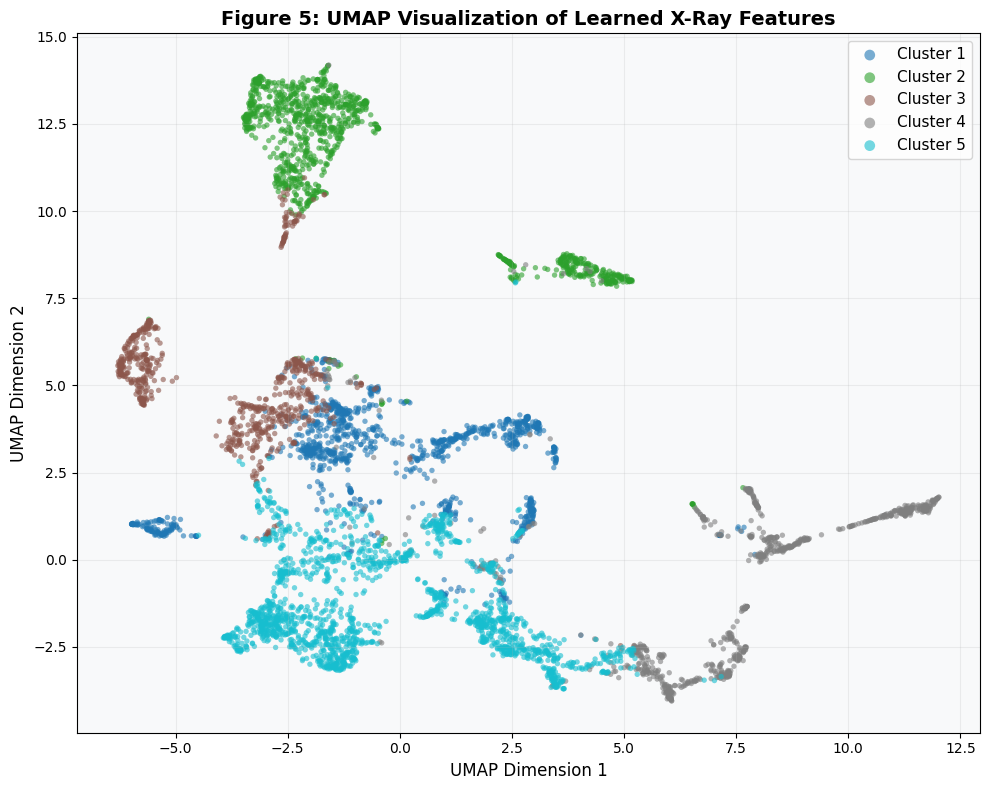

Figure 5 saved!


In [ ]:
print('Running UMAP...')
reducer = umap.UMAP(n_components=2, random_state=SEED)
features_umap = reducer.fit_transform(features_pca50)

fig, ax = plt.subplots(figsize=(10, 8))
for k in range(N_CLUSTERS):
    idx = cluster_labels == k
    ax.scatter(features_umap[idx, 0], features_umap[idx, 1],
               c=[colors[k]], label=f'Cluster {k+1}',
               alpha=0.6, s=15, edgecolors='none')
ax.set_xlabel('UMAP Dimension 1', fontsize=12)
ax.set_ylabel('UMAP Dimension 2', fontsize=12)
ax.set_title('Figure 5: UMAP Visualization of Learned X-Ray Features', fontsize=14, fontweight='bold')
ax.legend(fontsize=11, markerscale=2)
ax.grid(True, alpha=0.2)
ax.set_facecolor('#f8f9fa')
plt.tight_layout()
plt.savefig('figure5_umap.png', dpi=150, bbox_inches='tight')
plt.show()
print('Figure 5 saved!')

## FIGURE 6: Cluster Distribution & Silhouette Analysis

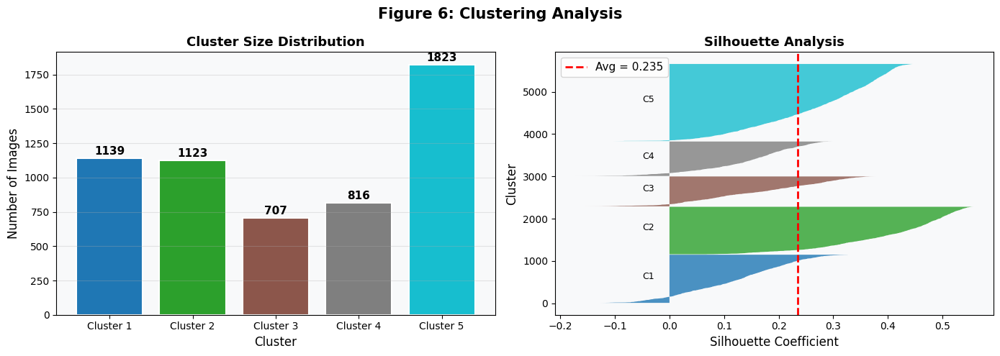

Figure 6 saved!


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Cluster size bar chart
cluster_counts = np.bincount(cluster_labels)
ax = axes[0]
bars = ax.bar(range(N_CLUSTERS), cluster_counts,
              color=[colors[k] for k in range(N_CLUSTERS)],
              edgecolor='white', linewidth=1.5)
for bar, count in zip(bars, cluster_counts):
    ax.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 10,
            str(count), ha='center', va='bottom', fontsize=11, fontweight='bold')
ax.set_xlabel('Cluster', fontsize=12)
ax.set_ylabel('Number of Images', fontsize=12)
ax.set_title('Cluster Size Distribution', fontsize=13, fontweight='bold')
ax.set_xticks(range(N_CLUSTERS))
ax.set_xticklabels([f'Cluster {k+1}' for k in range(N_CLUSTERS)])
ax.set_facecolor('#f8f9fa')
ax.grid(axis='y', alpha=0.3)

# Silhouette plot
sil_samples = silhouette_samples(features_pca50, cluster_labels)
ax2 = axes[1]
y_lower = 10
for k in range(N_CLUSTERS):
    sil_k = np.sort(sil_samples[cluster_labels == k])
    size_k = sil_k.shape[0]
    y_upper = y_lower + size_k
    ax2.fill_betweenx(np.arange(y_lower, y_upper), 0, sil_k,
                     facecolor=colors[k], alpha=0.8)
    ax2.text(-0.05, y_lower + 0.5*size_k, f'C{k+1}', fontsize=9)
    y_lower = y_upper + 10
ax2.axvline(x=sil_score, color='red', linestyle='--', linewidth=2,
            label=f'Avg = {sil_score:.3f}')
ax2.set_xlabel('Silhouette Coefficient', fontsize=12)
ax2.set_ylabel('Cluster', fontsize=12)
ax2.set_title('Silhouette Analysis', fontsize=13, fontweight='bold')
ax2.legend(fontsize=11)
ax2.set_facecolor('#f8f9fa')

fig.suptitle('Figure 6: Clustering Analysis', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.savefig('figure6_clustering.png', dpi=150, bbox_inches='tight')
plt.show()
print('Figure 6 saved!')

## FIGURE 7: Sample Images per Cluster

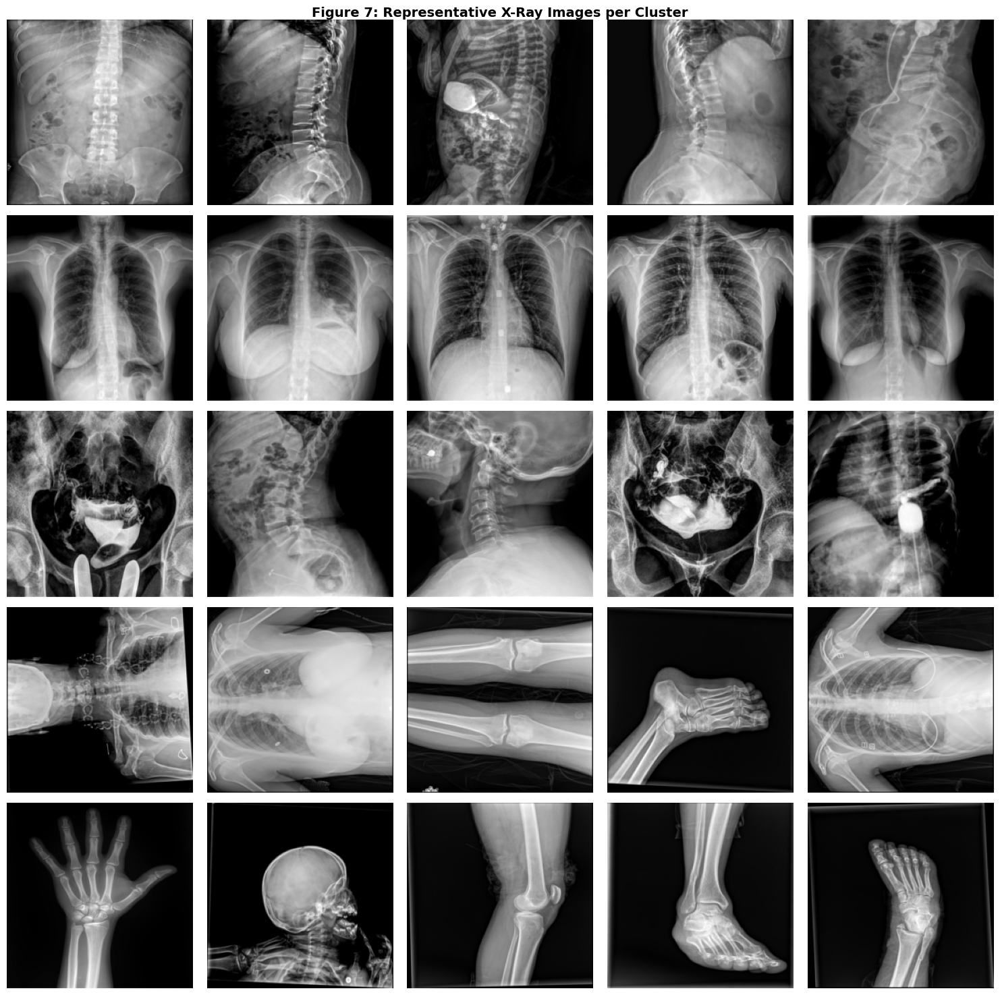

Figure 7 saved!


In [ ]:
N_SAMPLES_PER_CLUSTER = 5
fig, axes = plt.subplots(N_CLUSTERS, N_SAMPLES_PER_CLUSTER, figsize=(15, 3*N_CLUSTERS))

for k in range(N_CLUSTERS):
    cluster_indices = np.where(cluster_labels == k)[0]
    chosen = np.random.choice(cluster_indices, min(N_SAMPLES_PER_CLUSTER, len(cluster_indices)), replace=False)
    for j, idx in enumerate(chosen):
        img, _ = dataset[idx]
        img_dn = denormalize(img).permute(1,2,0).numpy().mean(axis=2)
        axes[k, j].imshow(img_dn, cmap='gray')
        axes[k, j].axis('off')
    axes[k, 0].set_ylabel(f'Cluster {k+1}\n({len(cluster_indices)} imgs)',
                          fontsize=11, fontweight='bold', rotation=90,
                          labelpad=5)

fig.suptitle('Figure 7: Representative X-Ray Images per Cluster', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('figure7_cluster_samples.png', dpi=150, bbox_inches='tight')
plt.show()
print('Figure 7 saved!')

## FIGURE 8: PCA Explained Variance

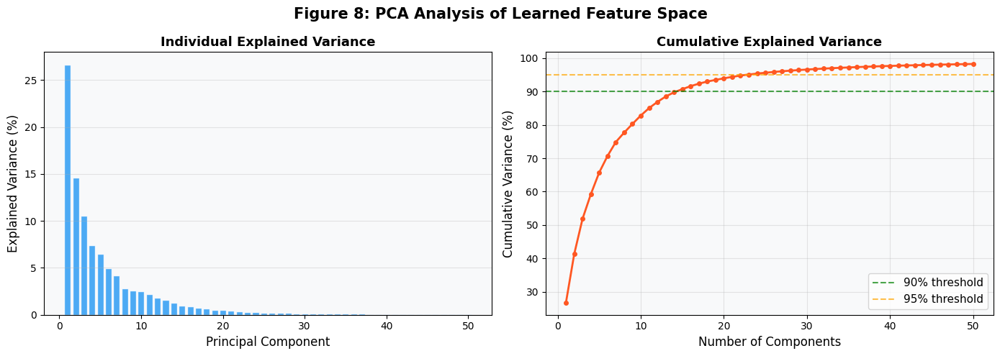

Figure 8 saved!


In [ ]:
pca_full = PCA(n_components=50, random_state=SEED)
pca_full.fit(features)
explained = np.cumsum(pca_full.explained_variance_ratio_) * 100

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
ax.bar(range(1, 51), pca_full.explained_variance_ratio_*100,
       color='#2196F3', alpha=0.8, edgecolor='white')
ax.set_xlabel('Principal Component', fontsize=12)
ax.set_ylabel('Explained Variance (%)', fontsize=12)
ax.set_title('Individual Explained Variance', fontsize=13, fontweight='bold')
ax.set_facecolor('#f8f9fa')
ax.grid(axis='y', alpha=0.3)

ax2 = axes[1]
ax2.plot(range(1, 51), explained, 'o-', color='#FF5722', linewidth=2, markersize=4)
ax2.axhline(y=90, color='green', linestyle='--', alpha=0.7, label='90% threshold')
ax2.axhline(y=95, color='orange', linestyle='--', alpha=0.7, label='95% threshold')
ax2.set_xlabel('Number of Components', fontsize=12)
ax2.set_ylabel('Cumulative Variance (%)', fontsize=12)
ax2.set_title('Cumulative Explained Variance', fontsize=13, fontweight='bold')
ax2.legend(fontsize=11)
ax2.set_facecolor('#f8f9fa')
ax2.grid(True, alpha=0.3)

fig.suptitle('Figure 8: PCA Analysis of Learned Feature Space', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.savefig('figure8_pca.png', dpi=150, bbox_inches='tight')
plt.show()
print('Figure 8 saved!')

## FIGURE 9: Reconstruction Quality at Different Epochs

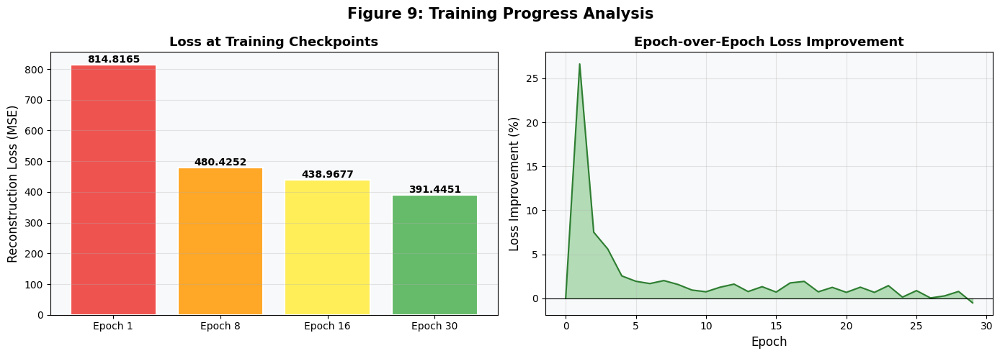

Figure 9 saved!


In [ ]:
# Loss improvement visualization
checkpoints = [0, len(train_losses)//4, len(train_losses)//2, len(train_losses)-1]
checkpoint_losses = [train_losses[i] for i in checkpoints]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Loss at checkpoints
ax = axes[0]
ep_labels = [f'Epoch {checkpoints[i]+1}' for i in range(4)]
bars = ax.bar(ep_labels, checkpoint_losses,
              color=['#EF5350','#FFA726','#FFEE58','#66BB6A'],
              edgecolor='white', linewidth=1.5)
for bar, val in zip(bars, checkpoint_losses):
    ax.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 0.001,
            f'{val:.4f}', ha='center', va='bottom', fontsize=10, fontweight='bold')
ax.set_ylabel('Reconstruction Loss (MSE)', fontsize=12)
ax.set_title('Loss at Training Checkpoints', fontsize=13, fontweight='bold')
ax.set_facecolor('#f8f9fa')
ax.grid(axis='y', alpha=0.3)

# Improvement rate
ax2 = axes[1]
improvement = [0] + [-(train_losses[i]-train_losses[i-1])/train_losses[i-1]*100
                     for i in range(1, len(train_losses))]
ax2.fill_between(range(len(improvement)), improvement, alpha=0.4, color='#4CAF50')
ax2.plot(improvement, color='#2E7D32', linewidth=1.5)
ax2.axhline(y=0, color='black', linewidth=0.8, linestyle='-')
ax2.set_xlabel('Epoch', fontsize=12)
ax2.set_ylabel('Loss Improvement (%)', fontsize=12)
ax2.set_title('Epoch-over-Epoch Loss Improvement', fontsize=13, fontweight='bold')
ax2.set_facecolor('#f8f9fa')
ax2.grid(True, alpha=0.3)

fig.suptitle('Figure 9: Training Progress Analysis', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.savefig('figure9_training_progress.png', dpi=150, bbox_inches='tight')
plt.show()
print('Figure 9 saved!')

## FIGURE 10: Pairwise Cluster Feature Distance Heatmap

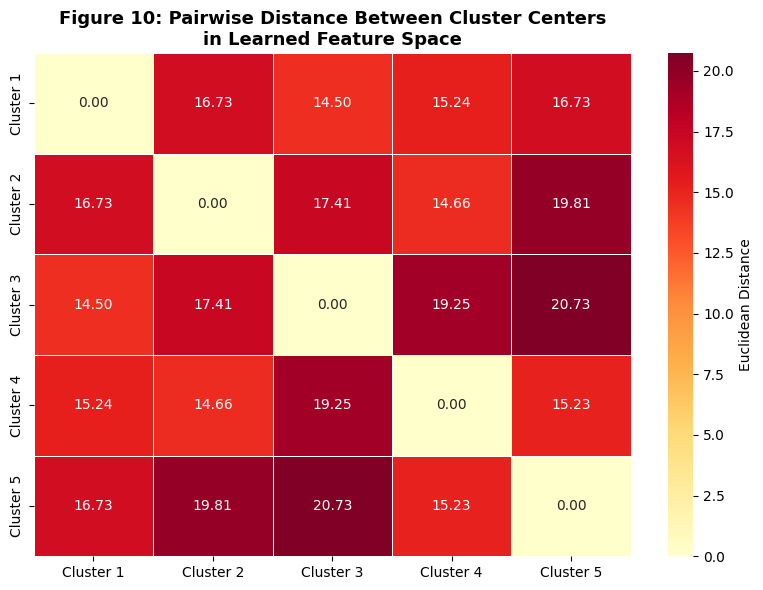

Figure 10 saved!


In [ ]:
cluster_centers = np.array([features_pca50[cluster_labels == k].mean(axis=0)
                             for k in range(N_CLUSTERS)])

dist_matrix = np.zeros((N_CLUSTERS, N_CLUSTERS))
for i in range(N_CLUSTERS):
    for j in range(N_CLUSTERS):
        dist_matrix[i, j] = np.linalg.norm(cluster_centers[i] - cluster_centers[j])

fig, ax = plt.subplots(figsize=(8, 6))
labels = [f'Cluster {k+1}' for k in range(N_CLUSTERS)]
sns.heatmap(dist_matrix, annot=True, fmt='.2f', cmap='YlOrRd',
            xticklabels=labels, yticklabels=labels, ax=ax,
            linewidths=0.5, cbar_kws={'label': 'Euclidean Distance'})
ax.set_title('Figure 10: Pairwise Distance Between Cluster Centers\nin Learned Feature Space',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('figure10_cluster_distance.png', dpi=150, bbox_inches='tight')
plt.show()
print('Figure 10 saved!')

## FIGURE 11: Optimal Number of Clusters (Elbow + Silhouette)

K=2: Inertia=1196189.8, Silhouette=0.1940
K=3: Inertia=1028109.7, Silhouette=0.2185
K=4: Inertia=940471.9, Silhouette=0.2245
K=5: Inertia=855524.2, Silhouette=0.2350
K=6: Inertia=790720.2, Silhouette=0.2353
K=7: Inertia=746265.7, Silhouette=0.2383
K=8: Inertia=704803.3, Silhouette=0.2228
K=9: Inertia=664957.1, Silhouette=0.2346
K=10: Inertia=641252.5, Silhouette=0.1999


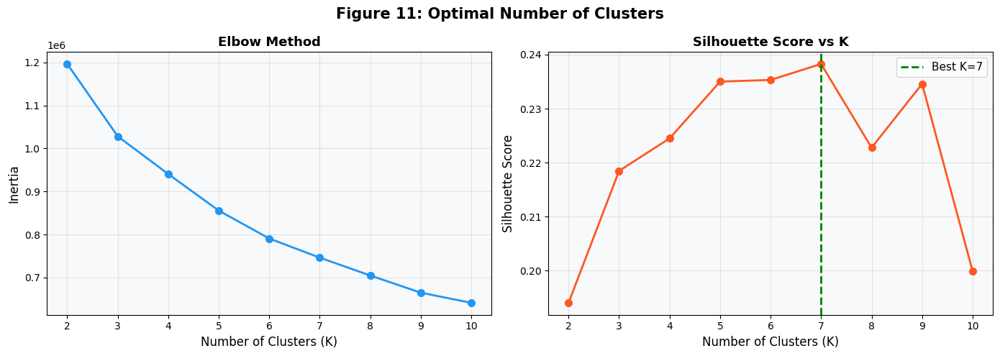

Figure 11 saved!


In [ ]:
K_range = range(2, 11)
inertias, sil_scores = [], []
for k in K_range:
    km = KMeans(n_clusters=k, random_state=SEED, n_init=5)
    labels_k = km.fit_predict(features_pca50)
    inertias.append(km.inertia_)
    sil_scores.append(silhouette_score(features_pca50, labels_k))
    print(f'K={k}: Inertia={km.inertia_:.1f}, Silhouette={sil_scores[-1]:.4f}')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
ax.plot(K_range, inertias, 'o-', color='#2196F3', linewidth=2, markersize=7)
ax.set_xlabel('Number of Clusters (K)', fontsize=12)
ax.set_ylabel('Inertia', fontsize=12)
ax.set_title('Elbow Method', fontsize=13, fontweight='bold')
ax.set_facecolor('#f8f9fa')
ax.grid(True, alpha=0.3)

ax2 = axes[1]
best_k = list(K_range)[np.argmax(sil_scores)]
ax2.plot(K_range, sil_scores, 'o-', color='#FF5722', linewidth=2, markersize=7)
ax2.axvline(x=best_k, color='green', linestyle='--', linewidth=2,
            label=f'Best K={best_k}')
ax2.set_xlabel('Number of Clusters (K)', fontsize=12)
ax2.set_ylabel('Silhouette Score', fontsize=12)
ax2.set_title('Silhouette Score vs K', fontsize=13, fontweight='bold')
ax2.legend(fontsize=11)
ax2.set_facecolor('#f8f9fa')
ax2.grid(True, alpha=0.3)

fig.suptitle('Figure 11: Optimal Number of Clusters', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.savefig('figure11_optimal_k.png', dpi=150, bbox_inches='tight')
plt.show()
print('Figure 11 saved!')

## FIGURE 12: Attention Map / Feature Heatmap Visualization

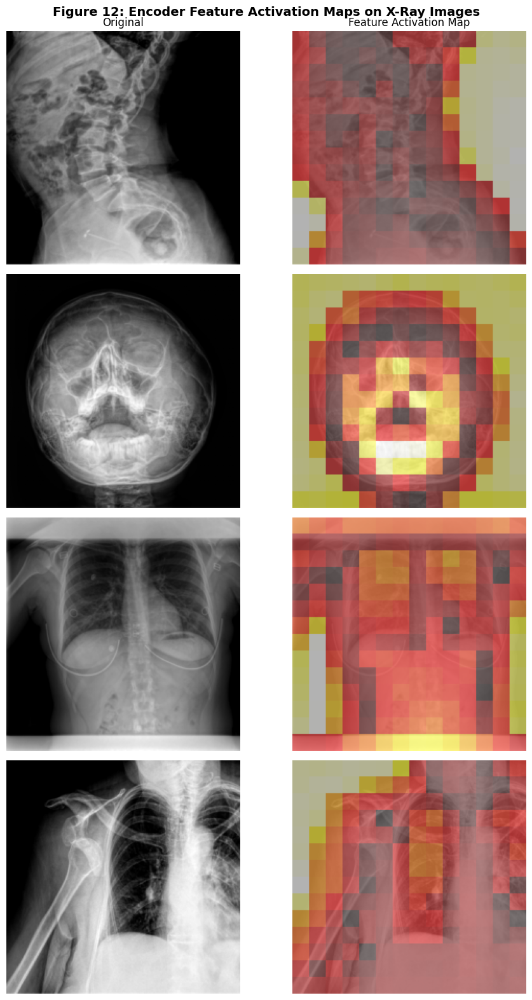

Figure 12 saved!


In [ ]:
# Feature-based heatmap: show which patches have highest activation
model.eval()
n_show = 4
sample_imgs = torch.stack([dataset[i][0] for i in range(n_show)]).to(device)

with torch.no_grad():
    patches = model.patchify(sample_imgs)
    tokens = model.patch_embed(patches) + model.pos_embed
    encoded = model.encoder_norm(model.encoder(tokens))
    # Activation magnitude per patch
    patch_activations = encoded.norm(dim=-1).cpu().numpy()  # (B, N_patches)

n_patches_side = IMG_SIZE // PATCH_SIZE

fig, axes = plt.subplots(n_show, 2, figsize=(10, 4*n_show))
for i in range(n_show):
    img = denormalize(sample_imgs[i].cpu()).permute(1,2,0).numpy().mean(axis=2)
    axes[i, 0].imshow(img, cmap='gray')
    axes[i, 0].axis('off')
    axes[i, 0].set_title('Original' if i == 0 else '', fontsize=12)

    heatmap = patch_activations[i].reshape(n_patches_side, n_patches_side)
    heatmap_up = np.kron(heatmap, np.ones((PATCH_SIZE, PATCH_SIZE)))  # upsample
    axes[i, 1].imshow(img, cmap='gray', alpha=0.6)
    axes[i, 1].imshow(heatmap_up, cmap='hot', alpha=0.5)
    axes[i, 1].axis('off')
    axes[i, 1].set_title('Feature Activation Map' if i == 0 else '', fontsize=12)

fig.suptitle('Figure 12: Encoder Feature Activation Maps on X-Ray Images',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('figure12_activation_maps.png', dpi=150, bbox_inches='tight')
plt.show()
print('Figure 12 saved!')

## Save All Figures to Google Drive

In [ ]:
import shutil

FIGURES_SAVE_PATH = '/content/drive/MyDrive/xray_paper_figures'
os.makedirs(FIGURES_SAVE_PATH, exist_ok=True)

figure_files = [f for f in os.listdir('/content') if f.endswith('.png')]
for f in figure_files:
    shutil.copy(f'/content/{f}', os.path.join(FIGURES_SAVE_PATH, f))
    print(f'Saved: {f}')

print(f'\nAll {len(figure_files)} figures saved to Google Drive: {FIGURES_SAVE_PATH}')

Saved: figure7_cluster_samples.png
Saved: figure12_activation_maps.png
Saved: figure3_training_curves.png
Saved: figure5_umap.png
Saved: figure2_reconstruction.png
Saved: figure4_tsne.png
Saved: figure1_dataset_samples.png
Saved: figure6_clustering.png
Saved: figure8_pca.png
Saved: figure9_training_progress.png
Saved: figure10_cluster_distance.png
Saved: figure11_optimal_k.png

All 12 figures saved to Google Drive: /content/drive/MyDrive/xray_paper_figures


Saved: figure1_dataset_samples.png


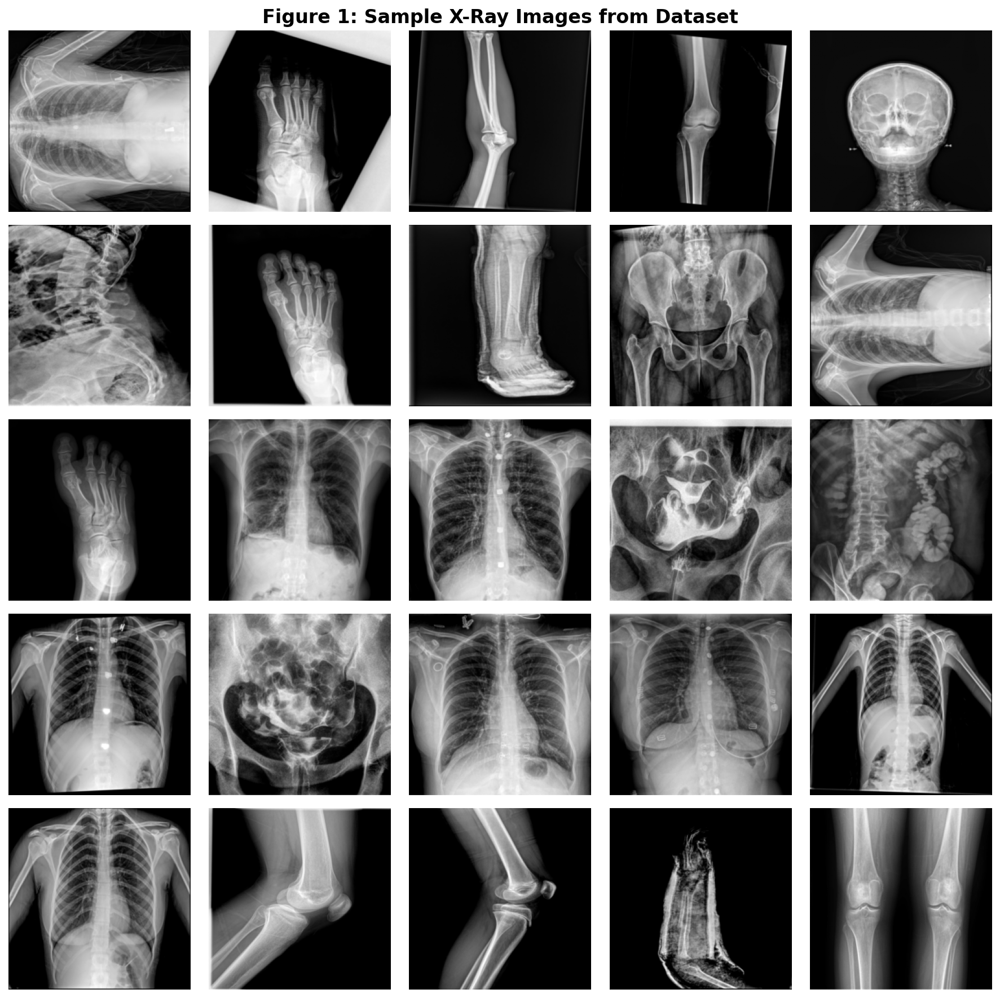

Saved: figure2_reconstruction.png


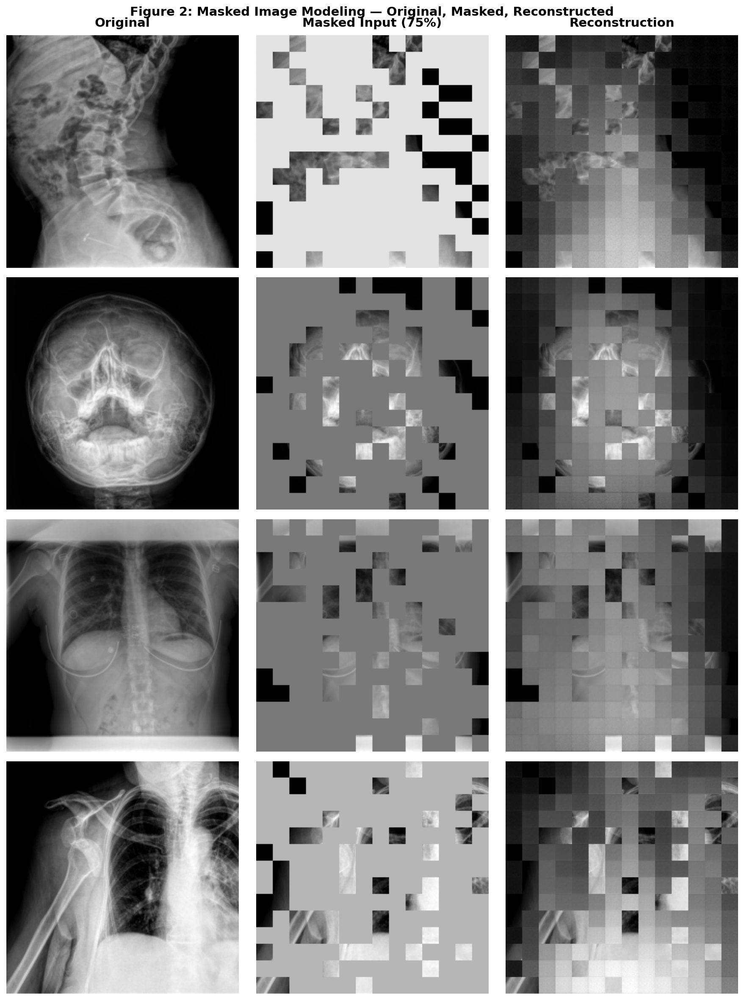

Saved: figure3_training_curves.png


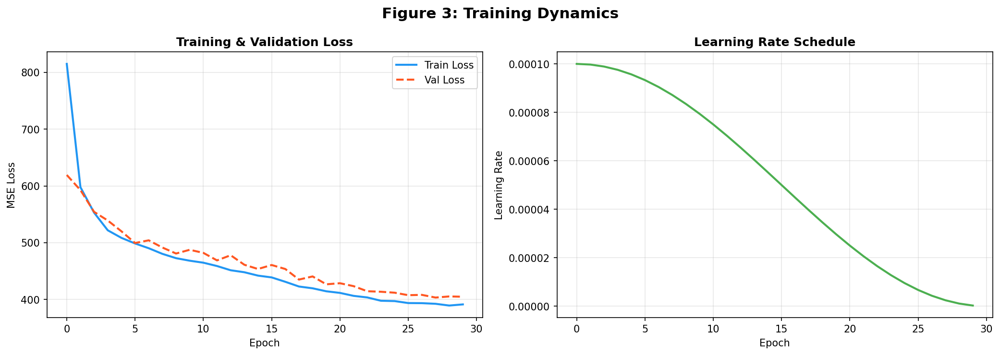

Extracting features...
Features: (5608, 768)
Silhouette Score: 0.2350
Running t-SNE...


/usr/local/lib/python3.12/dist-packages/sklearn/manifold/_t_sne.py:1164: FutureWarning: 'n_iter' was renamed to 'max_iter' in version 1.5 and will be removed in 1.7.
  warnings.warn(


Saved: figure4_tsne.png


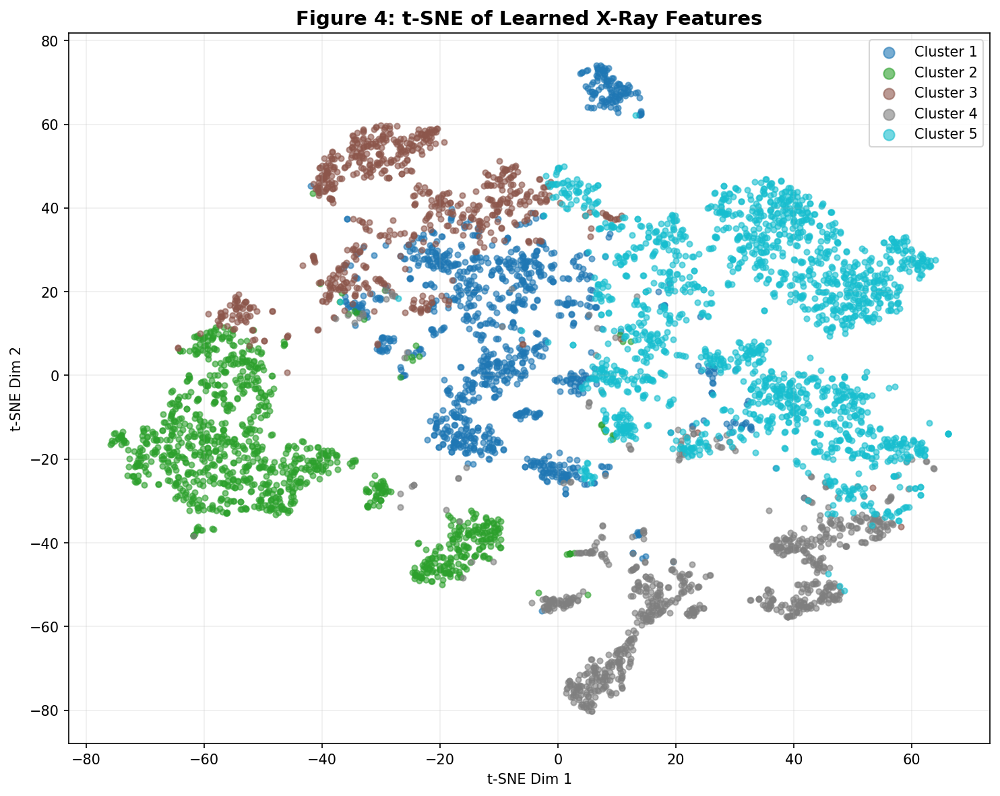

Running UMAP...


/usr/local/lib/python3.12/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Saved: figure5_umap.png


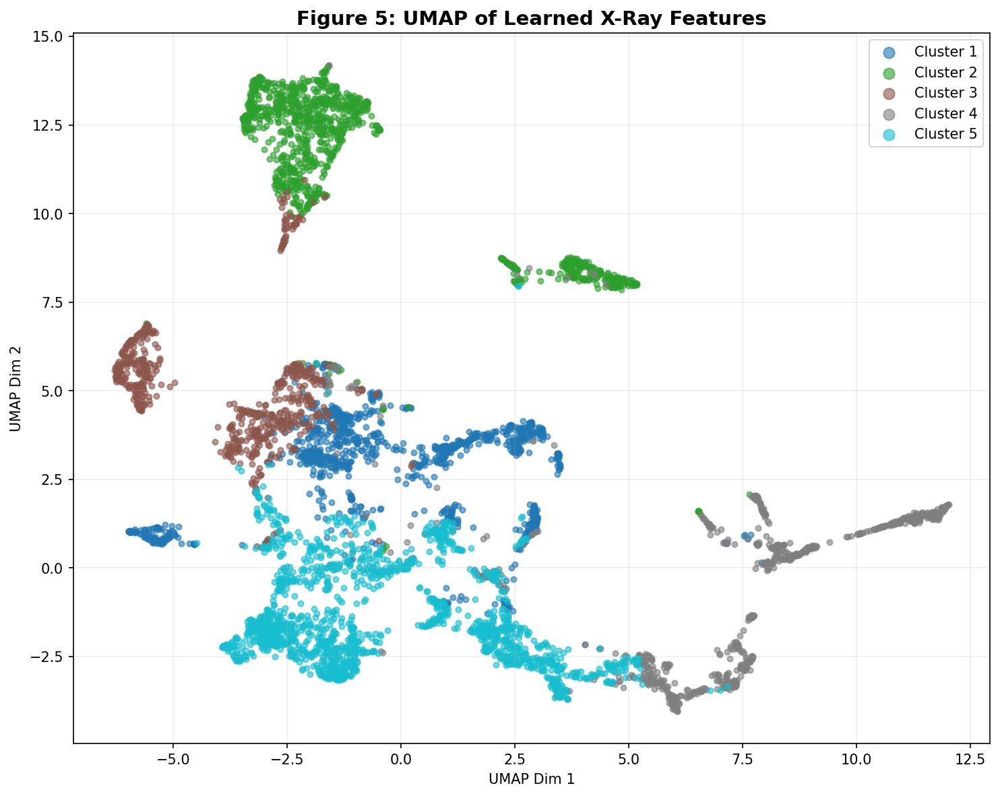

Saved: figure6_clustering.png


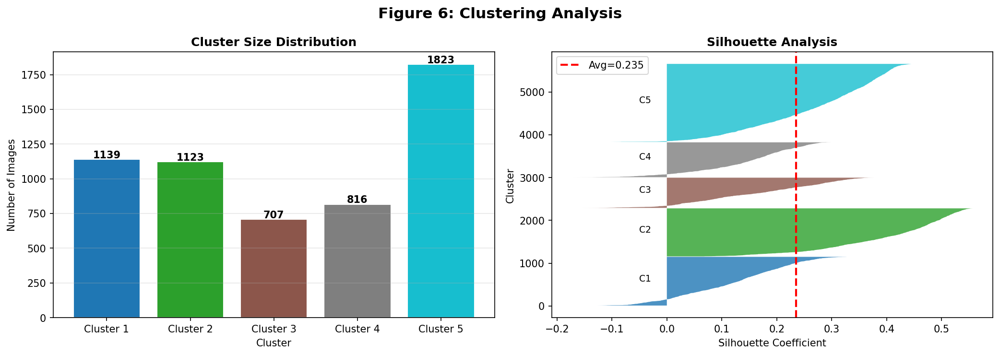

Saved: figure7_cluster_samples.png


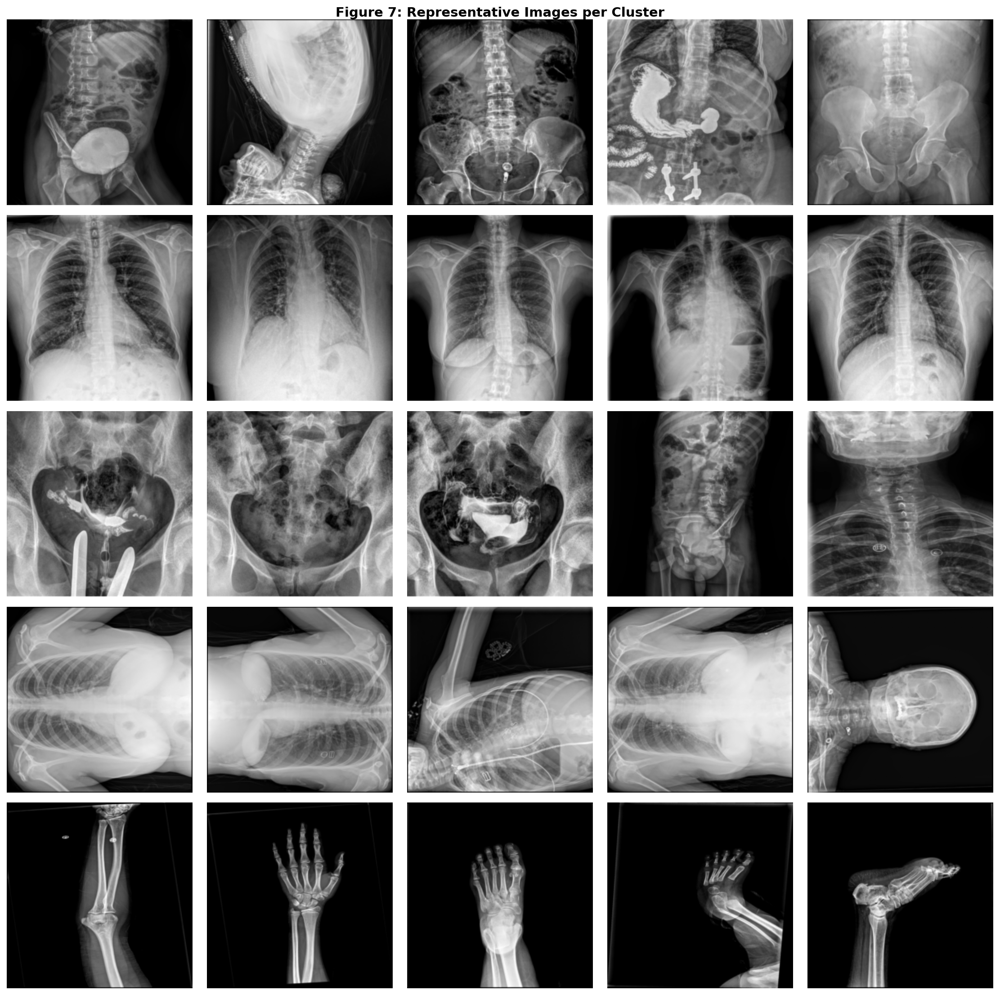

Saved: figure8_pca.png


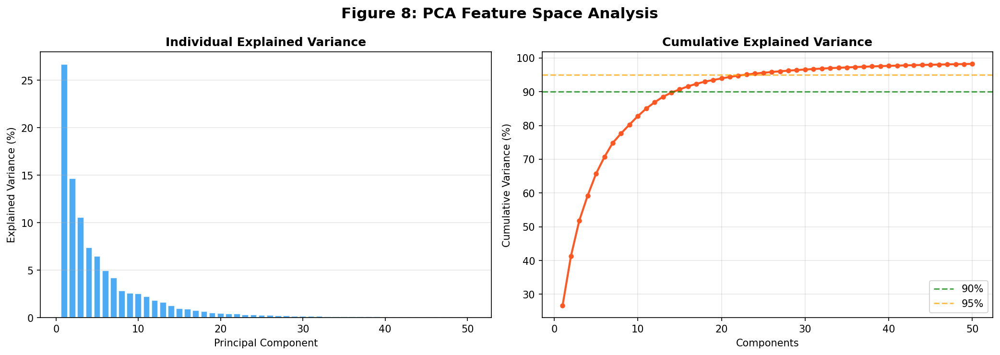

Saved: figure9_training_progress.png


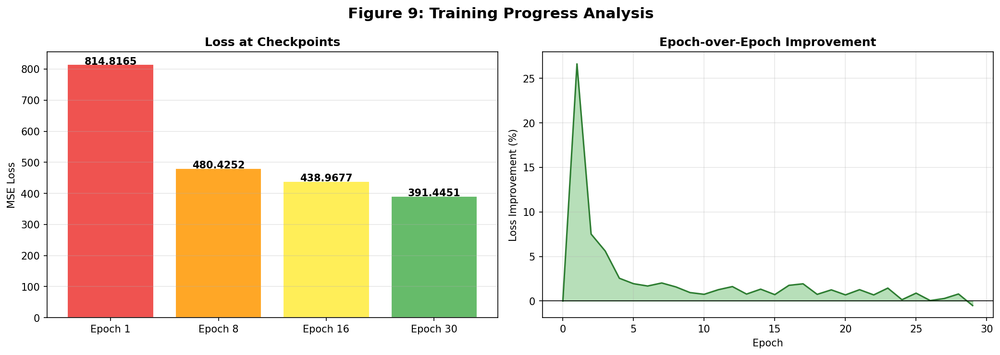

Saved: figure10_cluster_distance.png


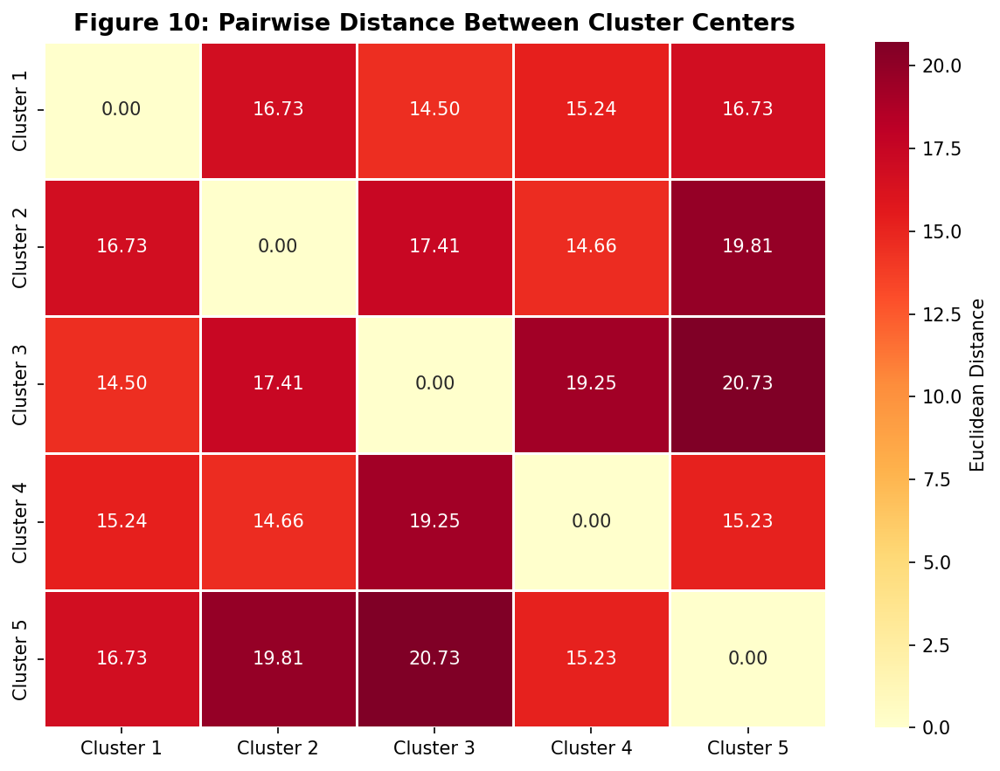

Computing optimal K...
  K=2: Silhouette=0.1940
  K=3: Silhouette=0.2185
  K=4: Silhouette=0.2245
  K=5: Silhouette=0.2350
  K=6: Silhouette=0.2353
  K=7: Silhouette=0.2383
  K=8: Silhouette=0.2228
  K=9: Silhouette=0.2346
  K=10: Silhouette=0.1999
Saved: figure11_optimal_k.png


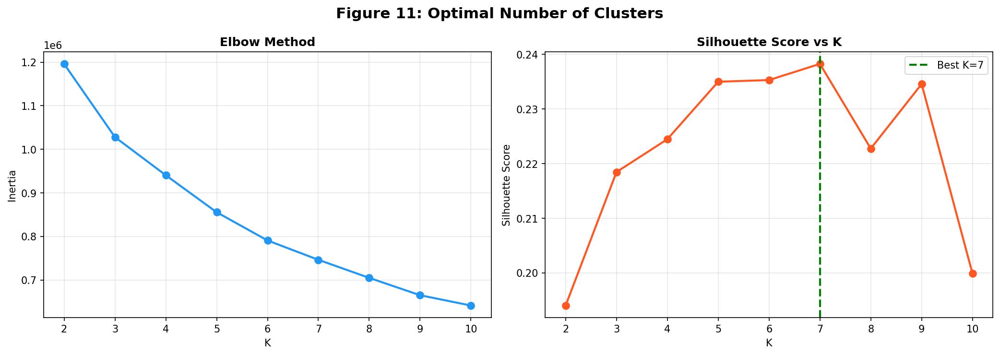

Saved: figure12_activation_maps.png


In [ ]:
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
import random, os, shutil
import numpy as np
import torch
from IPython.display import Image as IPImage, display
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, silhouette_samples
from sklearn.decomposition import PCA
import umap

SAVE_PATH = '/content/drive/MyDrive/xray_paper_figures'
os.makedirs(SAVE_PATH, exist_ok=True)

def denormalize(tensor):
    mean = torch.tensor([0.485, 0.456, 0.406]).view(3,1,1)
    std  = torch.tensor([0.229, 0.224, 0.225]).view(3,1,1)
    return torch.clamp(tensor * std + mean, 0, 1)

def save_and_show(fig, filename):
    path = os.path.join(SAVE_PATH, filename)
    fig.savefig(path, dpi=150, bbox_inches='tight')
    plt.close(fig)
    print(f'Saved: {filename}')
    display(IPImage(path))

# ─────────────────────────────────────────
# FIGURE 1: Dataset Sample Grid
# ─────────────────────────────────────────
sample_indices = random.sample(range(len(dataset)), 25)
sample_imgs_dn = torch.stack([denormalize(dataset[i][0]) for i in sample_indices])

fig, axes = plt.subplots(5, 5, figsize=(12, 12))
fig.suptitle('Figure 1: Sample X-Ray Images from Dataset', fontsize=16, fontweight='bold')
for i, ax in enumerate(axes.flat):
    ax.imshow(sample_imgs_dn[i].permute(1,2,0).numpy().mean(axis=2), cmap='gray')
    ax.axis('off')
plt.tight_layout()
save_and_show(fig, 'figure1_dataset_samples.png')

# ─────────────────────────────────────────
# FIGURE 2: Original → Masked → Reconstructed
# ─────────────────────────────────────────
def reconstruct_image(model, img_tensor, mask_row, pred_row):
    with torch.no_grad():
        target = model.patchify(img_tensor)
        masked_patches = target.clone()
        masked_patches[0][mask_row[0].bool()] = 0
        masked_img = model.unpatchify(masked_patches)[0]
        recon_patches = target.clone()
        recon_patches[0][mask_row[0].bool()] = pred_row[0][mask_row[0].bool()]
        recon_img = model.unpatchify(recon_patches)[0]
    return masked_img, recon_img

model.eval()
sample_batch = torch.stack([dataset[i][0] for i in range(8)]).to(device)
with torch.no_grad():
    loss, pred, mask = model(sample_batch)

n_show = 4
fig, axes = plt.subplots(n_show, 3, figsize=(12, 4*n_show))
for j, title in enumerate(['Original', 'Masked Input (75%)', 'Reconstruction']):
    axes[0, j].set_title(title, fontsize=14, fontweight='bold', pad=10)
for i in range(n_show):
    orig          = denormalize(sample_batch[i].cpu())
    masked, recon = reconstruct_image(model, sample_batch[i].unsqueeze(0),
                                      mask[i].unsqueeze(0), pred[i].unsqueeze(0))
    masked        = denormalize(masked.cpu())
    recon         = denormalize(recon.cpu())
    for j, im in enumerate([orig, masked, recon]):
        axes[i, j].imshow(im.permute(1,2,0).numpy().mean(axis=2), cmap='gray')
        axes[i, j].axis('off')
fig.suptitle('Figure 2: Masked Image Modeling — Original, Masked, Reconstructed',
             fontsize=14, fontweight='bold')
plt.tight_layout()
save_and_show(fig, 'figure2_reconstruction.png')

# ─────────────────────────────────────────
# FIGURE 3: Training & Validation Loss
# ─────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(train_losses, label='Train Loss', color='#2196F3', linewidth=2)
axes[0].plot(val_losses,   label='Val Loss',   color='#FF5722', linewidth=2, linestyle='--')
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('MSE Loss')
axes[0].set_title('Training & Validation Loss', fontweight='bold')
axes[0].legend(); axes[0].grid(True, alpha=0.3)
axes[1].plot(lr_history, color='#4CAF50', linewidth=2)
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Learning Rate')
axes[1].set_title('Learning Rate Schedule', fontweight='bold')
axes[1].grid(True, alpha=0.3)
fig.suptitle('Figure 3: Training Dynamics', fontsize=15, fontweight='bold')
plt.tight_layout()
save_and_show(fig, 'figure3_training_curves.png')

# ─────────────────────────────────────────
# Extract features & cluster (needed for figs 4-12)
# ─────────────────────────────────────────
print('Extracting features...')
from torch.utils.data import DataLoader
full_loader = DataLoader(dataset, batch_size=64, shuffle=False, num_workers=2)
all_features, all_paths = [], []
model.eval()
with torch.no_grad():
    for imgs, paths in full_loader:
        imgs = imgs.to(device)
        feats = model.get_features(imgs)
        all_features.append(feats.cpu().numpy())
        all_paths.extend(paths)
features = np.concatenate(all_features, axis=0)
print(f'Features: {features.shape}')

N_CLUSTERS = 5
pca_50 = PCA(n_components=50, random_state=42)
features_pca50 = pca_50.fit_transform(features)
kmeans = KMeans(n_clusters=N_CLUSTERS, random_state=42, n_init=10)
cluster_labels = kmeans.fit_predict(features_pca50)
sil_score = silhouette_score(features_pca50, cluster_labels)
colors = plt.cm.tab10(np.linspace(0, 1, N_CLUSTERS))
print(f'Silhouette Score: {sil_score:.4f}')

# ─────────────────────────────────────────
# FIGURE 4: t-SNE
# ─────────────────────────────────────────
print('Running t-SNE...')
tsne = TSNE(n_components=2, perplexity=30, random_state=42, n_iter=1000)
features_2d = tsne.fit_transform(features_pca50)

fig, ax = plt.subplots(figsize=(10, 8))
for k in range(N_CLUSTERS):
    idx = cluster_labels == k
    ax.scatter(features_2d[idx,0], features_2d[idx,1],
               c=[colors[k]], label=f'Cluster {k+1}', alpha=0.6, s=15)
ax.set_xlabel('t-SNE Dim 1'); ax.set_ylabel('t-SNE Dim 2')
ax.set_title('Figure 4: t-SNE of Learned X-Ray Features', fontsize=14, fontweight='bold')
ax.legend(markerscale=2); ax.grid(True, alpha=0.2)
plt.tight_layout()
save_and_show(fig, 'figure4_tsne.png')

# ─────────────────────────────────────────
# FIGURE 5: UMAP
# ─────────────────────────────────────────
print('Running UMAP...')
reducer = umap.UMAP(n_components=2, random_state=42)
features_umap = reducer.fit_transform(features_pca50)

fig, ax = plt.subplots(figsize=(10, 8))
for k in range(N_CLUSTERS):
    idx = cluster_labels == k
    ax.scatter(features_umap[idx,0], features_umap[idx,1],
               c=[colors[k]], label=f'Cluster {k+1}', alpha=0.6, s=15)
ax.set_xlabel('UMAP Dim 1'); ax.set_ylabel('UMAP Dim 2')
ax.set_title('Figure 5: UMAP of Learned X-Ray Features', fontsize=14, fontweight='bold')
ax.legend(markerscale=2); ax.grid(True, alpha=0.2)
plt.tight_layout()
save_and_show(fig, 'figure5_umap.png')

# ─────────────────────────────────────────
# FIGURE 6: Cluster Distribution + Silhouette
# ─────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
cluster_counts = np.bincount(cluster_labels)
bars = axes[0].bar(range(N_CLUSTERS), cluster_counts,
                   color=[colors[k] for k in range(N_CLUSTERS)], edgecolor='white')
for bar, count in zip(bars, cluster_counts):
    axes[0].text(bar.get_x()+bar.get_width()/2., bar.get_height()+10,
                 str(count), ha='center', fontweight='bold')
axes[0].set_xlabel('Cluster'); axes[0].set_ylabel('Number of Images')
axes[0].set_title('Cluster Size Distribution', fontweight='bold')
axes[0].set_xticks(range(N_CLUSTERS))
axes[0].set_xticklabels([f'Cluster {k+1}' for k in range(N_CLUSTERS)])
axes[0].grid(axis='y', alpha=0.3)

sil_samples = silhouette_samples(features_pca50, cluster_labels)
y_lower = 10
for k in range(N_CLUSTERS):
    sil_k = np.sort(sil_samples[cluster_labels == k])
    y_upper = y_lower + sil_k.shape[0]
    axes[1].fill_betweenx(np.arange(y_lower, y_upper), 0, sil_k,
                          facecolor=colors[k], alpha=0.8)
    axes[1].text(-0.05, y_lower + 0.5*sil_k.shape[0], f'C{k+1}', fontsize=9)
    y_lower = y_upper + 10
axes[1].axvline(x=sil_score, color='red', linestyle='--', linewidth=2,
                label=f'Avg={sil_score:.3f}')
axes[1].set_xlabel('Silhouette Coefficient'); axes[1].set_ylabel('Cluster')
axes[1].set_title('Silhouette Analysis', fontweight='bold'); axes[1].legend()
fig.suptitle('Figure 6: Clustering Analysis', fontsize=15, fontweight='bold')
plt.tight_layout()
save_and_show(fig, 'figure6_clustering.png')

# ─────────────────────────────────────────
# FIGURE 7: Sample Images per Cluster
# ─────────────────────────────────────────
N_SAMPLES = 5
fig, axes = plt.subplots(N_CLUSTERS, N_SAMPLES, figsize=(15, 3*N_CLUSTERS))
for k in range(N_CLUSTERS):
    indices = np.where(cluster_labels == k)[0]
    chosen  = np.random.choice(indices, min(N_SAMPLES, len(indices)), replace=False)
    for j, idx in enumerate(chosen):
        img = denormalize(dataset[idx][0]).permute(1,2,0).numpy().mean(axis=2)
        axes[k, j].imshow(img, cmap='gray'); axes[k, j].axis('off')
    axes[k, 0].set_ylabel(f'Cluster {k+1}\n({len(indices)} imgs)',
                          fontsize=11, fontweight='bold')
fig.suptitle('Figure 7: Representative Images per Cluster', fontsize=14, fontweight='bold')
plt.tight_layout()
save_and_show(fig, 'figure7_cluster_samples.png')

# ─────────────────────────────────────────
# FIGURE 8: PCA Explained Variance
# ─────────────────────────────────────────
pca_full = PCA(n_components=50, random_state=42).fit(features)
explained = np.cumsum(pca_full.explained_variance_ratio_) * 100

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].bar(range(1,51), pca_full.explained_variance_ratio_*100,
            color='#2196F3', alpha=0.8, edgecolor='white')
axes[0].set_xlabel('Principal Component'); axes[0].set_ylabel('Explained Variance (%)')
axes[0].set_title('Individual Explained Variance', fontweight='bold')
axes[0].grid(axis='y', alpha=0.3)

axes[1].plot(range(1,51), explained, 'o-', color='#FF5722', linewidth=2, markersize=4)
axes[1].axhline(y=90, color='green',  linestyle='--', alpha=0.7, label='90%')
axes[1].axhline(y=95, color='orange', linestyle='--', alpha=0.7, label='95%')
axes[1].set_xlabel('Components'); axes[1].set_ylabel('Cumulative Variance (%)')
axes[1].set_title('Cumulative Explained Variance', fontweight='bold')
axes[1].legend(); axes[1].grid(True, alpha=0.3)
fig.suptitle('Figure 8: PCA Feature Space Analysis', fontsize=15, fontweight='bold')
plt.tight_layout()
save_and_show(fig, 'figure8_pca.png')

# ─────────────────────────────────────────
# FIGURE 9: Training Progress
# ─────────────────────────────────────────
checkpoints      = [0, len(train_losses)//4, len(train_losses)//2, len(train_losses)-1]
checkpoint_losses = [train_losses[i] for i in checkpoints]
improvement = [0] + [-(train_losses[i]-train_losses[i-1])/train_losses[i-1]*100
                     for i in range(1, len(train_losses))]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ep_labels = [f'Epoch {c+1}' for c in checkpoints]
bars = axes[0].bar(ep_labels, checkpoint_losses,
                   color=['#EF5350','#FFA726','#FFEE58','#66BB6A'], edgecolor='white')
for bar, val in zip(bars, checkpoint_losses):
    axes[0].text(bar.get_x()+bar.get_width()/2., bar.get_height()+0.001,
                 f'{val:.4f}', ha='center', fontweight='bold', fontsize=10)
axes[0].set_ylabel('MSE Loss'); axes[0].set_title('Loss at Checkpoints', fontweight='bold')
axes[0].grid(axis='y', alpha=0.3)

axes[1].fill_between(range(len(improvement)), improvement, alpha=0.4, color='#4CAF50')
axes[1].plot(improvement, color='#2E7D32', linewidth=1.5)
axes[1].axhline(y=0, color='black', linewidth=0.8)
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Loss Improvement (%)')
axes[1].set_title('Epoch-over-Epoch Improvement', fontweight='bold')
axes[1].grid(True, alpha=0.3)
fig.suptitle('Figure 9: Training Progress Analysis', fontsize=15, fontweight='bold')
plt.tight_layout()
save_and_show(fig, 'figure9_training_progress.png')

# ─────────────────────────────────────────
# FIGURE 10: Cluster Distance Heatmap
# ─────────────────────────────────────────
centers = np.array([features_pca50[cluster_labels==k].mean(axis=0) for k in range(N_CLUSTERS)])
dist_matrix = np.linalg.norm(centers[:,None] - centers[None,:], axis=-1)

fig, ax = plt.subplots(figsize=(8, 6))
labels = [f'Cluster {k+1}' for k in range(N_CLUSTERS)]
sns.heatmap(dist_matrix, annot=True, fmt='.2f', cmap='YlOrRd',
            xticklabels=labels, yticklabels=labels, ax=ax,
            linewidths=0.5, cbar_kws={'label': 'Euclidean Distance'})
ax.set_title('Figure 10: Pairwise Distance Between Cluster Centers',
             fontsize=13, fontweight='bold')
plt.tight_layout()
save_and_show(fig, 'figure10_cluster_distance.png')

# ─────────────────────────────────────────
# FIGURE 11: Optimal K (Elbow + Silhouette)
# ─────────────────────────────────────────
print('Computing optimal K...')
K_range = range(2, 11)
inertias, sil_scores_k = [], []
for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=5)
    lk = km.fit_predict(features_pca50)
    inertias.append(km.inertia_)
    sil_scores_k.append(silhouette_score(features_pca50, lk))
    print(f'  K={k}: Silhouette={sil_scores_k[-1]:.4f}')

best_k = list(K_range)[np.argmax(sil_scores_k)]
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(K_range, inertias, 'o-', color='#2196F3', linewidth=2, markersize=7)
axes[0].set_xlabel('K'); axes[0].set_ylabel('Inertia')
axes[0].set_title('Elbow Method', fontweight='bold'); axes[0].grid(True, alpha=0.3)

axes[1].plot(K_range, sil_scores_k, 'o-', color='#FF5722', linewidth=2, markersize=7)
axes[1].axvline(x=best_k, color='green', linestyle='--', linewidth=2, label=f'Best K={best_k}')
axes[1].set_xlabel('K'); axes[1].set_ylabel('Silhouette Score')
axes[1].set_title('Silhouette Score vs K', fontweight='bold')
axes[1].legend(); axes[1].grid(True, alpha=0.3)
fig.suptitle('Figure 11: Optimal Number of Clusters', fontsize=15, fontweight='bold')
plt.tight_layout()
save_and_show(fig, 'figure11_optimal_k.png')

# ─────────────────────────────────────────
# FIGURE 12: Feature Activation Maps
# ─────────────────────────────────────────
n_show = 4
sample_imgs = torch.stack([dataset[i][0] for i in range(n_show)]).to(device)
model.eval()
with torch.no_grad():
    patches  = model.patchify(sample_imgs)
    tokens   = model.patch_embed(patches) + model.pos_embed
    encoded  = model.encoder_norm(model.encoder(tokens))
    patch_activations = encoded.norm(dim=-1).cpu().numpy()

n_side = 224 // 16
fig, axes = plt.subplots(n_show, 2, figsize=(10, 4*n_show))
for i in range(n_show):
    img_gray = denormalize(sample_imgs[i].cpu()).permute(1,2,0).numpy().mean(axis=2)
    axes[i,0].imshow(img_gray, cmap='gray'); axes[i,0].axis('off')
    axes[i,0].set_title('Original' if i==0 else '', fontsize=12)
    heatmap = np.kron(patch_activations[i].reshape(n_side, n_side),
                      np.ones((16, 16)))
    axes[i,1].imshow(img_gray, cmap='gray', alpha=0.6)
    axes[i,1].imshow(heatmap, cmap='hot', alpha=0.5); axes[i,1].axis('off')
    axes[i,1].set_title('Activation Map' if i==0 else '', fontsize=12)
fig.suptitle('Figure 12: Encoder Feature Activation Maps', fontsize=14, fontweight='bold')
plt.tight_layout()
save_and_show(fig, 'figure12_activation_maps.png')

# ─────────────────────────────────────────
print(f'\n✅ All 12 figures saved to: {SAVE_PATH}')